<center><a href="https://www.nvidia.com/en-us/training/"><img src="https://dli-lms.s3.amazonaws.com/assets/general/DLI_Header_White.png" width="400" height="186" /></a></center>

# HS notes on the math

## Question:
Explain to me the math for forward diffusion.

## Answer:
Okay, let's break down these formulas used in Denoising Diffusion Probabilistic Models (DDPMs). It's common to find the notation a bit dense at first!

**Answer to Question 1: Understanding $N(x; \mu, \sigma^2)$**

* **What the Equation Represents:** This is the formula for the **Probability Density Function (PDF)** of a **Normal Distribution** (also known as a Gaussian distribution or bell curve).
* **What is 'x'?**
    * `x` is the **variable** or the specific **value** for which you want to know the probability density. Think of it as a possible outcome or a point on the horizontal axis of the bell curve.
    * The function $N(x; \mu, \sigma^2)$ takes a value `x` as input and tells you the "likelihood" or probability density associated with observing that specific value `x`.
* **Why is 'x' there?**
    * Without `x`, the formula wouldn't be a function describing the distribution of probabilities. It needs `x` to specify *which* value's probability density you're calculating.
    * Imagine the bell curve graph: `x` represents a position along the bottom (horizontal) axis, and the formula $N(x; \mu, \sigma^2)$ gives you the height of the curve at that specific position `x`.
* **What the Equation Says Exactly:**
    1.  $N(x; \mu, \sigma^2)$: This notation means "The Normal distribution's PDF evaluated at point `x`, for a distribution with mean $\mu$ and variance $\sigma^2$."
    2.  $\mu$ (mu): This is the **mean** or average value of the distribution. It's the center point of the bell curve, where the probability density is highest.
    3.  $\sigma^2$ (sigma squared): This is the **variance**. It measures how spread out the distribution is. A larger variance means a wider, flatter bell curve; a smaller variance means a narrower, taller curve. $\sigma$ (sigma) is the standard deviation.
    4.  $\frac{1}{\sigma\sqrt{2\pi}}$: This is a **normalization constant**. It ensures that the total area under the curve (representing the total probability of *all* possible outcomes) equals 1.
    5.  $e^{...}$: The exponential function $e$ raised to a power. This gives the formula its characteristic bell shape.
    6.  $-\frac{1}{2} \left(\frac{x-\mu}{\sigma}\right)^2$: This is the exponent.
        * $(x-\mu)$: How far the value `x` is from the mean $\mu$.
        * $\frac{x-\mu}{\sigma}$: How many standard deviations `x` is away from the mean (this is called the z-score).
        * Squaring this value makes it positive, ensuring the curve is symmetric around the mean.
        * Multiplying by $-1/2$ makes the exponent negative, so the probability density decreases as `x` gets further away from the mean $\mu$.

* **In the context of your notes:** When generating noise, you "sample" from this distribution. This means you randomly pick a value (`x`) according to the probabilities defined by this PDF. Often, you sample from a *standard* normal distribution where $\mu=0$ and $\sigma^2=1$, and then you might scale the result (multiply by a different $\sigma$) or shift it (add a different $\mu$) if needed. For adding noise to an image, this sampling is done independently for each pixel's color channel(s).

---

**Answer to Question 2: Understanding $q(\mathbf{x}_t | \mathbf{x}_{t-1})$**

* **What the Equation Represents:** This equation defines one step in the **forward diffusion process**. It describes the probability distribution of the image state $\mathbf{x}_t$ at timestep $t$, *given* the image state $\mathbf{x}_{t-1}$ at the previous timestep $t-1$. The 'q' signifies that this is part of the known, defined forward process (as opposed to the learned reverse process, often denoted 'p').
* **What is '$\mathbf{x}_t$'?** (Note the bold font, often indicating a vector or tensor)
    * $\mathbf{x}_t$ represents the **state of the entire image at timestep t**. It's a collection of all pixel values.
    * Similar to `x` in the first formula, $\mathbf{x}_t$ here is the **variable** of this specific probability distribution. The formula defines the probability density for *any potential* image $\mathbf{x}_t$ that could result at step $t$.
* **Why is '$\mathbf{x}_t$' there?**
    * It's the outcome whose probability we are describing. The function $q(\mathbf{x}_t | \mathbf{x}_{t-1})$ takes a potential resulting image $\mathbf{x}_t$ as input (conceptually) and tells you its probability density, *assuming* you started with $\mathbf{x}_{t-1}$.
    * It's essential for defining the transition probability: what's the likelihood of transitioning *to* state $\mathbf{x}_t$ *from* state $\mathbf{x}_{t-1}$ in one step?
* **What the Equation Says Exactly:**
    1.  $q(\mathbf{x}_t | \mathbf{x}_{t-1})$: Reads as "The probability distribution of $\mathbf{x}_t$ given $\mathbf{x}_{t-1}$." This is a **conditional probability distribution**.
    2.  $= N(\mathbf{x}_t; ..., ...)$: It states that this conditional distribution *is* a Normal (Gaussian) distribution. Since $\mathbf{x}_t$ represents an entire image (a high-dimensional vector), this is technically a multivariate Normal distribution.
    3.  **Mean:** $\sqrt{1-\beta_t} \cdot \mathbf{x}_{t-1}$. The mean (average expected outcome) for the image at step $t$ is the image from the previous step $\mathbf{x}_{t-1}$ scaled down by a factor of $\sqrt{1-\beta_t}$. Since $\beta_t$ is small and positive, $\sqrt{1-\beta_t}$ is slightly less than 1. This means the previous image is slightly "faded" or attenuated. Remember $\alpha_t = 1-\beta_t$, so the mean is $\sqrt{\alpha_t} \mathbf{x}_{t-1}$.
    4.  **Covariance Matrix:** $\beta_t \cdot \mathbf{I}$.
        * In a multivariate Normal distribution, variance is generalized to a covariance matrix $\Sigma$.
        * $\mathbf{I}$ is the **identity matrix** (1s on the diagonal, 0s elsewhere).
        * Multiplying $\mathbf{I}$ by $\beta_t$ means the covariance matrix is diagonal with $\beta_t$ for each diagonal element.
        * This signifies that the noise added to each pixel (and channel) is **independent** (zero covariance between different pixels) and each has a **variance** of $\beta_t$. $\beta_t$ comes from your "variance schedule" at step $t$.
    5.  **In essence:** The formula says: to get the image $\mathbf{x}_t$ from $\mathbf{x}_{t-1}$, take $\mathbf{x}_{t-1}$, scale it down by $\sqrt{1-\beta_t}$, and add Gaussian noise with mean 0 and variance $\beta_t$ independently to each pixel/channel.

* **Connecting to the Code:**
    * The code `noise = torch.randn_like(x_t)` generates noise from a *standard* normal distribution (mean 0, variance 1) with the same shape as the image.
    * `torch.sqrt(B[t]) * noise` scales this noise so it now has variance $\beta_t$ (because Variance(c*X) = c^2 * Variance(X), so scaling by $\sqrt{\beta_t}$ gives variance $(\sqrt{\beta_t})^2 * 1 = \beta_t$). This corresponds to the $\beta_t \mathbf{I}$ term in the formula (it's the noise part).
    * `torch.sqrt(1 - B[t]) * x_t` (assuming `x_t` here conceptually represents `x_{t-1}` before the update) calculates the scaled-down previous image, which is the mean of the distribution.
    * Adding them: `x_t = torch.sqrt(1 - B[t]) * x_t_minus_1 + torch.sqrt(B[t]) * noise` (corrected variable name for clarity) exactly implements sampling one $\mathbf{x}_t$ according to the distribution $q(\mathbf{x}_t | \mathbf{x}_{t-1})$. It constructs a *sample* from that distribution.

In summary, the first formula defines the general shape of Gaussian noise, while the second formula uses that definition to specify exactly *how much* noise ($\beta_t$) is added and how the previous image ($\mathbf{x}_{t-1}$) is scaled at each specific step ($t$) of the forward diffusion process. $\mathbf{x}_t$ is the resulting noisy image variable whose probability distribution is being defined by that second equation.

## Question:
Explain to me the reverse diffusion. 

## Answer:
Okay, let's dive into the reverse diffusion process formulas. This is where the "magic" of generation happens by learning to undo the noise addition.

**Formula 1: The Target Reverse Distribution**

$p(\mathbf{x}_{t-1} | \mathbf{x}_t) = N(\mathbf{x}_{t-1}; \boldsymbol{\mu}_\theta(\mathbf{x}_t, t), \boldsymbol{\Sigma}_\theta(\mathbf{x}_t, t))$

* **What the Equation Represents:** This equation defines the **target probability distribution for a single step backwards in time**. It describes the probability of the slightly *less* noisy image $\mathbf{x}_{t-1}$, given that we currently have the *more* noisy image $\mathbf{x}_t$. The goal of the entire training process is to create a model that can approximate this distribution.
* **What is '$\mathbf{x}_{t-1}$'?** Similar to before, $\mathbf{x}_{t-1}$ is the **variable** of this distribution. It represents the image state at the previous (less noisy) timestep $t-1$. The formula gives the probability density for any possible candidate image $\mathbf{x}_{t-1}$.
* **Why is '$\mathbf{x}_{t-1}$' there?** It's the outcome whose probability we want to determine. The function $p(\mathbf{x}_{t-1} | \mathbf{x}_t)$ answers the question: "Given the noisy image $\mathbf{x}_t$, how likely is it that the image at the previous step was $\mathbf{x}_{t-1}$?"
* **What the Equation Says Exactly:**
    1.  $p(\mathbf{x}_{t-1} | \mathbf{x}_t)$: The conditional probability distribution of $\mathbf{x}_{t-1}$ given $\mathbf{x}_t$. 'p' usually denotes the reverse (learned) process.
    2.  $N(...; ..., ...)$: We *assume* that this reverse step can also be modeled by a Normal (Gaussian) distribution.
    3.  $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t)$: This is the **mean** of the Gaussian. It represents the *predicted* average image state at step $t-1$, based on the current state $\mathbf{x}_t$ and the timestep $t$. The subscript $\theta$ is crucial: it signifies that this mean is not known beforehand but is **calculated by our neural network** (whose learnable parameters are denoted by $\theta$).
    4.  $\boldsymbol{\Sigma}_\theta(\mathbf{x}_t, t)$: This is the **covariance matrix** (the multidimensional equivalent of variance) of the Gaussian. It represents the uncertainty or the spread of possible images $\mathbf{x}_{t-1}$ around the predicted mean $\boldsymbol{\mu}_\theta$. This is also typically dependent on the network $\theta$, the current image $\mathbf{x}_t$, and timestep $t$.
* **Connecting to the Notes:** Your notes correctly identify 'p' as the distribution for removing noise. The key point mentioned is that this distribution $p(\mathbf{x}_{t-1} | \mathbf{x}_t)$ is **unknown and difficult to calculate directly** ("intractable"). This is precisely *why* we need a neural network: its task is to learn a function (parameterized by $\theta$) that approximates this intractable distribution, specifically by predicting its mean $\boldsymbol{\mu}_\theta$ and covariance $\boldsymbol{\Sigma}_\theta$.

---

**Formula 2: The Tractable Forward Process Posterior**

$q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0) = N(\mathbf{x}_{t-1}; \tilde{\boldsymbol{\mu}}(\mathbf{x}_t, \mathbf{x}_0), \tilde{\beta}_t \cdot \mathbf{I})$
where $\tilde{\beta}_t = \frac{1-\bar{\alpha}_{t-1}}{1-\bar{\alpha}_t} \beta_t$

* **What the Equation Represents:** This looks similar to the first equation, but it's fundamentally different. This is **not** the reverse process $p$. Instead, this is the **true posterior distribution derived from the known forward process $q$**. It answers the question: "If we know how we got from $\mathbf{x}_0$ to $\mathbf{x}_t$ using the *forward* noising process, what is the probability distribution of the intermediate step $\mathbf{x}_{t-1}$?" Crucially, this distribution is **mathematically tractable** (we can write down its exact form) because it only depends on the known forward process $q$ and the known noise schedule ($\beta_t$, $\alpha_t$, $\bar{\alpha}_t$).
* **Why is it important?** Because the true reverse distribution $p(\mathbf{x}_{t-1}|\mathbf{x}_t)$ is intractable, we need a target that our network *can* learn to approximate. This tractable distribution $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$ serves as that target! The core idea of DDPMs is to train the neural network $p_\theta(\mathbf{x}_{t-1} | \mathbf{x}_t)$ to match this true posterior $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$.
* **What is '$\mathbf{x}_{t-1}$'?** Again, it's the variable of the distribution – the image state at step $t-1$.
* **Why is '$\mathbf{x}_{t-1}$' there?** The formula describes the probability density for different possible values of the intermediate image $\mathbf{x}_{t-1}$, given we know where we started ($\mathbf{x}_0$) and where we ended up ($\mathbf{x}_t$) in the forward process.
* **What the Equation Says Exactly:**
    1.  $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$: The conditional probability of $\mathbf{x}_{t-1}$ given *both* the later noisy image $\mathbf{x}_t$ and the *original clean image* $\mathbf{x}_0$.
    2.  $N(...; ..., ...)$: This true posterior distribution also turns out to be Gaussian.
    3.  $\tilde{\boldsymbol{\mu}}(\mathbf{x}_t, \mathbf{x}_0)$: The **mean** of this posterior Gaussian. Its exact formula (derived using Bayes' theorem on the forward process steps) depends on $\mathbf{x}_t$, $\mathbf{x}_0$, and the noise schedule parameters ($\alpha_t, \beta_t, \bar{\alpha}_t$, where $\bar{\alpha}_t = \prod_{i=1}^t \alpha_i$). The next formula will give more insight into this.
    4.  $\tilde{\beta}_t \cdot \mathbf{I}$: The **covariance matrix**. It's diagonal with variance $\tilde{\beta}_t$ for each pixel.
    5.  $\tilde{\beta}_t = \frac{1-\bar{\alpha}_{t-1}}{1-\bar{\alpha}_t} \beta_t$: This is the **posterior variance**. Notice it only depends on the known noise schedule parameters. It's a fixed, calculated value for each timestep $t$.
* **Connecting to the Notes:** The notes correctly state this is derived by reversing the known $q$ distribution and that it depends on $\mathbf{x}_t$ and $\mathbf{x}_0$. Because $\tilde{\beta}_t$ is known and fixed, the network $p_\theta$ often doesn't need to learn the covariance $\boldsymbol{\Sigma}_\theta$. Instead, $\boldsymbol{\Sigma}_\theta$ is often set to $\tilde{\beta}_t \mathbf{I}$ (or sometimes even $\beta_t \mathbf{I}$ as a simplification). The main task for the network $\theta$ is then to learn the mean $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t)$ such that it approximates $\tilde{\boldsymbol{\mu}}(\mathbf{x}_t, \mathbf{x}_0)$.

---

**Formula 3: The Posterior Mean in Terms of Noise**

$\tilde{\boldsymbol{\mu}}_t(\mathbf{x}_t, \mathbf{x}_0) = \frac{1}{\sqrt{\alpha_t}} \left( \mathbf{x}_t - \frac{1-\alpha_t}{\sqrt{1-\bar{\alpha}_t}} \boldsymbol{\epsilon}_t \right)$
(where $\boldsymbol{\epsilon}_t$ is the noise added at time $t$, assuming $\mathbf{x}_t = \sqrt{\bar{\alpha}_t}\mathbf{x}_0 + \sqrt{1-\bar{\alpha}_t}\boldsymbol{\epsilon}_t$)

* **What the Equation Represents:** This provides the mathematical formula for the **mean $\tilde{\boldsymbol{\mu}}_t$** of the tractable posterior distribution $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$. Importantly, it's expressed here not directly using $\mathbf{x}_0$, but using the current noisy image $\mathbf{x}_t$ and the underlying standard Gaussian noise $\boldsymbol{\epsilon}_t$ that would be required to generate $\mathbf{x}_t$ from $\mathbf{x}_0$ in the forward process using the formula $\mathbf{x}_t = \sqrt{\bar{\alpha}_t}\mathbf{x}_0 + \sqrt{1-\bar{\alpha}_t}\boldsymbol{\epsilon}_t$.
* **Why is it important?** This formulation is the key insight for training the network!
    * We want our learned mean $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t)$ to approximate this $\tilde{\boldsymbol{\mu}}_t$.
    * This formula shows that $\tilde{\boldsymbol{\mu}}_t$ can be calculated if we know $\mathbf{x}_t$ and the noise $\boldsymbol{\epsilon}_t$.
    * Therefore, instead of training the neural network to directly predict the complex mean $\boldsymbol{\mu}_\theta$, we can train it to **predict the noise** $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ that was likely added to get $\mathbf{x}_t$.
    * Once the network predicts the noise $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$, we can plug *that prediction* into this formula (in place of the true $\boldsymbol{\epsilon}_t$) to calculate our desired mean $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t)$.
* **What the Components Mean:**
    * $\tilde{\boldsymbol{\mu}}_t$: The target mean we want to approximate.
    * $\alpha_t = 1-\beta_t$: Noise schedule parameter.
    * $\bar{\alpha}_t = \prod_{i=1}^t \alpha_i$: Cumulative noise schedule parameter.
    * $\mathbf{x}_t$: The input noisy image at step $t$.
    * $\boldsymbol{\epsilon}_t$: The standard Gaussian noise associated with generating $\mathbf{x}_t$ from $\mathbf{x}_0$. **This is what the neural network learns to predict.**
* **Connecting to the Notes:** Your notes perfectly capture this: "$\boldsymbol{\epsilon}_t$ is the noise added at time $t$" (more accurately, the total noise component in $\mathbf{x}_t$) and "This is what the neural network will estimate". The network $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ takes the noisy image $\mathbf{x}_t$ and the timestep $t$ as input and outputs a prediction of the noise $\boldsymbol{\epsilon}_t$. This prediction is then used in the formula above to get the mean $\boldsymbol{\mu}_\theta$ needed for the reverse sampling step.

---

**In Summary:**

1.  **Goal:** We want to sample from the reverse distribution $p(\mathbf{x}_{t-1}|\mathbf{x}_t)$ to go from noise $\mathbf{x}_T$ back to a clean image $\mathbf{x}_0$.
2.  **Problem:** This distribution is intractable.
3.  **Solution:** We approximate it with a learned Gaussian $p_\theta(\mathbf{x}_{t-1} | \mathbf{x}_t) = N(\mathbf{x}_{t-1}; \boldsymbol{\mu}_\theta(\mathbf{x}_t, t), \boldsymbol{\Sigma}_\theta(\mathbf{x}_t, t))$.
4.  **Target:** We train $p_\theta$ to match the *tractable* true forward posterior $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0) = N(\mathbf{x}_{t-1}; \tilde{\boldsymbol{\mu}}(\mathbf{x}_t, \mathbf{x}_0), \tilde{\beta}_t \cdot \mathbf{I})$.
5.  **Simplification:** We often fix the learned variance $\boldsymbol{\Sigma}_\theta$ to be the known posterior variance $\tilde{\beta}_t \mathbf{I}$ (or $\beta_t \mathbf{I}$).
6.  **Network Task:** The network $\theta$ learns to predict the mean $\boldsymbol{\mu}_\theta$. It does this *indirectly* by predicting the noise component $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$.
7.  **Using the Prediction:** The predicted noise $\boldsymbol{\epsilon}_\theta$ is plugged into the formula $\boldsymbol{\mu}_\theta = \frac{1}{\sqrt{\alpha_t}} \left( \mathbf{x}_t - \frac{1-\alpha_t}{\sqrt{1-\bar{\alpha}_t}} \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t) \right)$ to get the required mean for the reverse step.
8.  **Generation:** Start with random noise $\mathbf{x}_T$. Repeatedly use the network to predict noise $\boldsymbol{\epsilon}_\theta$, calculate the mean $\boldsymbol{\mu}_\theta$, and sample $\mathbf{x}_{t-1}$ from $N(\mathbf{x}_{t-1}; \boldsymbol{\mu}_\theta, \tilde{\beta}_t \mathbf{I})$ until you reach $\mathbf{x}_0$.

## Question:
If we have a probability distribution for an outcome (say q or p in here corresonding to PDF of an X), then how do we find the likeliest value (i.e. X with highest probablity) for that PDF?

## Answer:

For any given probability distribution, finding the value with the highest probability (or probability density) is equivalent to finding the **mode** of the distribution.

Here's how it applies to the distributions we've discussed, which are Normal (Gaussian) distributions:

1.  **Normal Distribution Property:** A key property of the Normal distribution $N(x; \mu, \sigma^2)$ (or its multivariate counterpart $N(\mathbf{x}; \boldsymbol{\mu}, \boldsymbol{\Sigma})$) is that its Probability Density Function (PDF) has a single peak, and this peak occurs exactly at the **mean** ($\mu$ or $\boldsymbol{\mu}$).

    * Think of the bell curve shape: the highest point of the curve is always located at the mean value. Values closer to the mean have higher probability density, and values farther away have lower density.

2.  **Applying to DDPM Distributions:**
    * **Forward Process Step:** For the distribution $q(\mathbf{x}_t | \mathbf{x}_{t-1}) = N(\mathbf{x}_t; \sqrt{1-\beta_t} \mathbf{x}_{t-1}, \beta_t \mathbf{I})$, the value of $\mathbf{x}_t$ with the highest probability density, given $\mathbf{x}_{t-1}$, is its mean: $\sqrt{1-\beta_t} \mathbf{x}_{t-1}$.
    * **Reverse Process Step (Learned):** For the distribution $p_\theta(\mathbf{x}_{t-1} | \mathbf{x}_t) = N(\mathbf{x}_{t-1}; \boldsymbol{\mu}_\theta(\mathbf{x}_t, t), \sigma_t^2 \mathbf{I})$, the value of $\mathbf{x}_{t-1}$ that the model considers most likely, given $\mathbf{x}_t$, is its mean: $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t)$.
    * **Forward Process Posterior (Target):** For the distribution $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0) = N(\mathbf{x}_{t-1}; \tilde{\boldsymbol{\mu}}(\mathbf{x}_t, \mathbf{x}_0), \tilde{\beta}_t \mathbf{I})$, the value of $\mathbf{x}_{t-1}$ with the highest probability density, given both $\mathbf{x}_t$ and $\mathbf{x}_0$, is its mean: $\tilde{\boldsymbol{\mu}}(\mathbf{x}_t, \mathbf{x}_0)$.

**In summary:** For the Gaussian distributions used in DDPMs (both the forward $q$ distributions and the learned reverse $p_\theta$ distributions), the value `X` (which represents the image state $\mathbf{x}_t$ or $\mathbf{x}_{t-1}$) that has the highest probability density according to the PDF is simply the **mean** of that specific Gaussian distribution.

**Important Distinction: Mode vs. Sampling**

While the mean ($\boldsymbol{\mu}_\theta(\mathbf{x}_t, t)$) is the single *most likely* value for $\mathbf{x}_{t-1}$ according to the reverse distribution $p_\theta$, the actual generation process in DDPMs involves **sampling** from that distribution:

$\mathbf{x}_{t-1} = \boldsymbol{\mu}_\theta(\mathbf{x}_t, t) + \sigma_t \times \mathbf{z}$ (except possibly at t=1)

This means we don't just take the most likely value (the mean). Instead, we take the mean and add appropriately scaled random noise ($\sigma_t \times \mathbf{z}$). This stochasticity (randomness introduced by $\mathbf{z}$) at each step is crucial for generating diverse and high-quality samples. If you only took the mean at each step, the generation process would be deterministic (after choosing the initial noise $\mathbf{x}_T$) and might lead to less varied or potentially lower-fidelity results.

## Question:
For a given step t, once I have calculated he mean μθ, how to I actually generate the image Xt-1 ? what's the code + explaination of steps?

## Answer:
Okay, great question! You've used your neural network ($\boldsymbol{\epsilon}_\theta$) to predict the noise, and then used that prediction in the formula to calculate the mean $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t)$ for the reverse step. Now you want to actually generate the image $\mathbf{x}_{t-1}$ using this mean.

Here's how you do it:

**1. Recall the Distribution You're Sampling From:**

You are trying to draw a sample $\mathbf{x}_{t-1}$ from the learned reverse distribution:
$p_\theta(\mathbf{x}_{t-1} | \mathbf{x}_t) = N(\mathbf{x}_{t-1}; \boldsymbol{\mu}_\theta(\mathbf{x}_t, t), \boldsymbol{\Sigma}_\theta(\mathbf{x}_t, t))$

**2. Determine the Variance/Covariance $\boldsymbol{\Sigma}_\theta$:**

As discussed, the network usually only learns the mean $\boldsymbol{\mu}_\theta$. The covariance $\boldsymbol{\Sigma}_\theta$ is typically *fixed* beforehand to be a diagonal matrix $\sigma_t^2 \mathbf{I}$. There are two common choices for the variance $\sigma_t^2$:

* **Choice A: $\sigma_t^2 = \tilde{\beta}_t = \frac{1-\bar{\alpha}_{t-1}}{1-\bar{\alpha}_t} \beta_t$** (Posterior variance). This theoretically makes $p_\theta$ closer to the target $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$ when $\mathbf{x}_0$ is known.
* **Choice B: $\sigma_t^2 = \beta_t$** (Forward process variance). This is simpler and was found to work well in the original DDPM paper, especially for likelihood estimation, although Choice A might be slightly better for sample quality.

You need to choose one of these (or follow the specific implementation you're using). Let's assume you have chosen one and call the variance $\sigma_t^2$. The standard deviation is then $\sigma_t = \sqrt{\sigma_t^2}$.

**3. Sampling from the Gaussian:**

To draw a sample $\mathbf{x}_{t-1}$ from a Gaussian distribution $N(\boldsymbol{\mu}, \sigma^2 \mathbf{I})$, the standard procedure is:

$\text{sample} = \text{mean} + (\text{standard deviation}) \times (\text{standard Gaussian noise})$

Applying this to our context:

$\mathbf{x}_{t-1} = \boldsymbol{\mu}_\theta(\mathbf{x}_t, t) + \sigma_t \times \mathbf{z}$

where $\mathbf{z}$ is a random sample drawn from a standard Normal distribution $N(\mathbf{0}, \mathbf{I})$ (mean 0, variance 1) and has the same shape as your image $\mathbf{x}_t$.

**4. Special Case: The Final Step (t=1):**

When you are performing the very last step of the reverse process (i.e., calculating $\mathbf{x}_0$ from $\mathbf{x}_1$), the noise term $\sigma_t \times \mathbf{z}$ is usually **omitted**. The mean $\boldsymbol{\mu}_\theta(\mathbf{x}_1, 1)$ itself is taken as the final generated image $\mathbf{x}_0$. The reasoning is that the variance $\sigma_1^2$ (either $\beta_1$ or $\tilde{\beta}_1$) is typically very small, and adding random noise at the very end can slightly degrade the quality of the final output.

**5. Steps and Code (PyTorch-like):**

Let's assume:
* `x_t`: The current noisy image tensor at step `t`.
* `t`: The current timestep (e.g., an integer tensor, often iterated from T down to 1).
* `model`: Your trained neural network ($\boldsymbol{\epsilon}_\theta$).
* `get_mu_theta(model_output, x_t, t)`: A function that takes the predicted noise `model_output` ($\boldsymbol{\epsilon}_\theta$) and calculates $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t)$ using the formula from before.
* `get_sigma_t(t)`: A function that returns the standard deviation $\sigma_t$ (i.e., $\sqrt{\beta_t}$ or $\sqrt{\tilde{\beta}_t}$) for timestep `t` based on your chosen variance schedule and variance type.
* We are iterating `t` from `T` down to `1`.

```python
import torch

# Assume x_t, t, model, get_mu_theta, get_sigma_t are defined

# 1. Predict the noise using the network
# Make sure model is in evaluation mode if applicable (e.g., for dropout/batchnorm)
# model.eval()
with torch.no_grad(): # Disable gradient calculations during inference
    predicted_noise = model(x_t, t) # Epsilon_theta(x_t, t)

# 2. Calculate the mean (mu_theta) using the formula
mu_theta = get_mu_theta(predicted_noise, x_t, t)
# Example implementation for get_mu_theta might look like:
# def get_mu_theta(predicted_noise, x_t, t):
#     alpha_t = get_alpha_t(t) # Get alpha_t = 1 - beta_t
#     alpha_t_bar = get_alpha_t_bar(t) # Get cumulative product up to t
#     term1 = 1 / torch.sqrt(alpha_t)
#     term2 = (1 - alpha_t) / torch.sqrt(1 - alpha_t_bar)
#     mu = term1 * (x_t - term2 * predicted_noise)
#     return mu

# 3. Get the standard deviation for this timestep
sigma_t = get_sigma_t(t)
# Example implementation for get_sigma_t (Choice B: sqrt(beta_t))
# def get_sigma_t(t):
#     beta_t = get_beta_t(t) # Get beta_t from schedule
#     return torch.sqrt(beta_t)
# Example implementation for get_sigma_t (Choice A: sqrt(tilde_beta_t))
# def get_sigma_t(t):
#     beta_t = get_beta_t(t)
#     alpha_t_bar = get_alpha_t_bar(t)
#     alpha_t_bar_prev = get_alpha_t_bar(t-1) # Handle t=0/1 case carefully here
#     tilde_beta_t = (1 - alpha_t_bar_prev) / (1 - alpha_t_bar) * beta_t
#     return torch.sqrt(tilde_beta_t)


# 4. Generate standard Gaussian noise (z)
# z should have the same shape as x_t
z = torch.randn_like(x_t)

# 5. Calculate x_{t-1}
# Apply noise only if t > 1 (not the final step)
if t > 1: # Check if current timestep is greater than 1
    x_t_minus_1 = mu_theta + sigma_t * z
else: # If t=1, this is the final step -> x_0
    x_t_minus_1 = mu_theta # No noise added

# Now x_t_minus_1 is ready to be used as x_t in the next iteration (for t-1)
# print(f"Generated x_{t-1} from x_{t}")
# x_t = x_t_minus_1 # Update for the next loop iteration

```

**Explanation of Steps in Code:**

1.  **Predict Noise:** Feed the current image `x_t` and timestep `t` into your trained neural network (`model`) to get the predicted noise `predicted_noise` ($\boldsymbol{\epsilon}_\theta$). We use `torch.no_grad()` because we are doing inference, not training.
2.  **Calculate Mean:** Use the `predicted_noise` and the formula $\boldsymbol{\mu}_\theta = \frac{1}{\sqrt{\alpha_t}} ( \mathbf{x}_t - \frac{1-\alpha_t}{\sqrt{1-\bar{\alpha}_t}} \boldsymbol{\epsilon}_\theta )$ to compute the mean `mu_theta`. This requires having functions to get the noise schedule parameters ($\alpha_t, \bar{\alpha}_t$) for the given `t`.
3.  **Get Standard Deviation:** Retrieve the pre-determined standard deviation `sigma_t` (either $\sqrt{\beta_t}$ or $\sqrt{\tilde{\beta}_t}$) corresponding to the current timestep `t`.
4.  **Generate Noise `z`:** Create a tensor `z` of the same shape as `x_t`, filled with random numbers sampled from a standard Gaussian distribution (mean 0, variance 1) using `torch.randn_like()`.
5.  **Sample `x_{t-1}`:** Check if the current timestep `t` is the last step (`t=1`).
    * If `t > 1`, apply the full sampling formula: `x_t_minus_1 = mu_theta + sigma_t * z`.
    * If `t = 1`, omit the noise term: `x_t_minus_1 = mu_theta`.
    This `x_t_minus_1` is your generated image for the previous timestep. In a full generation loop, you would assign this result back to `x_t` and repeat the process for `t-1`.

## Question:
How do we arrive at the Formula 3: The Posterior Mean in Terms of Noise?

## Answer:
Okay, let's break down the derivation of that formula for the posterior mean $\tilde{\boldsymbol{\mu}}_t$ and clarify the role of $\mathbf{x}_0$ and $\boldsymbol{\epsilon}_t$.

**The Goal:**

We want to find the parameters (specifically the mean $\tilde{\boldsymbol{\mu}}_t$) of the posterior distribution $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$. This distribution tells us about the likely state at $t-1$ given the state at $t$ *and* the original image $\mathbf{x}_0$, assuming the known forward noising process $q$.

**Key Ingredients:**

1.  **Forward Step:** $\mathbf{x}_t = \sqrt{\alpha_t} \mathbf{x}_{t-1} + \sqrt{\beta_t} \mathbf{z}_{t-1}$, where $\mathbf{z}_{t-1} \sim N(\mathbf{0}, \mathbf{I})$ and $\alpha_t = 1-\beta_t$. This means $q(\mathbf{x}_t | \mathbf{x}_{t-1}) = N(\mathbf{x}_t; \sqrt{\alpha_t} \mathbf{x}_{t-1}, \beta_t \mathbf{I})$.
2.  **Forward Process (to $\mathbf{x}_0$):** $\mathbf{x}_t = \sqrt{\bar{\alpha}_t} \mathbf{x}_0 + \sqrt{1-\bar{\alpha}_t} \boldsymbol{\epsilon}_t$, where $\boldsymbol{\epsilon}_t \sim N(\mathbf{0}, \mathbf{I})$ and $\bar{\alpha}_t = \prod_{i=1}^t \alpha_i$. This means $q(\mathbf{x}_t | \mathbf{x}_0) = N(\mathbf{x}_t; \sqrt{\bar{\alpha}_t} \mathbf{x}_0, (1-\bar{\alpha}_t) \mathbf{I})$.
    * Similarly, $q(\mathbf{x}_{t-1} | \mathbf{x}_0) = N(\mathbf{x}_{t-1}; \sqrt{\bar{\alpha}_{t-1}} \mathbf{x}_0, (1-\bar{\alpha}_{t-1}) \mathbf{I})$.
3.  **Bayes' Theorem:** For probability densities, $q(A|B,C) \propto q(B|A,C) q(A|C)$. Applying this:
    $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0) \propto q(\mathbf{x}_t | \mathbf{x}_{t-1}, \mathbf{x}_0) q(\mathbf{x}_{t-1} | \mathbf{x}_0)$.
4.  **Markov Property:** The forward process is Markovian, so $\mathbf{x}_t$ depends only on $\mathbf{x}_{t-1}$. Thus, $q(\mathbf{x}_t | \mathbf{x}_{t-1}, \mathbf{x}_0) = q(\mathbf{x}_t | \mathbf{x}_{t-1})$.
    So, $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0) \propto q(\mathbf{x}_t | \mathbf{x}_{t-1}) q(\mathbf{x}_{t-1} | \mathbf{x}_0)$.

**Derivation Sketch (Focusing on Exponents):**

We know the posterior $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$ is Gaussian, let's say $N(\mathbf{x}_{t-1}; \tilde{\boldsymbol{\mu}}_t, \tilde{\beta}_t \mathbf{I})$. Its PDF is proportional to $\exp(-\frac{1}{2\tilde{\beta}_t} ||\mathbf{x}_{t-1} - \tilde{\boldsymbol{\mu}}_t||^2)$.

From Bayes' theorem, the exponent of $q(\mathbf{x}_{t-1} | \mathbf{x}_t, \mathbf{x}_0)$ is (up to constants):
Exponent $\propto -\frac{1}{2\beta_t} ||\mathbf{x}_t - \sqrt{\alpha_t} \mathbf{x}_{t-1}||^2 -\frac{1}{2(1-\bar{\alpha}_{t-1})} ||\mathbf{x}_{t-1} - \sqrt{\bar{\alpha}_{t-1}} \mathbf{x}_0||^2$

We need to rearrange this exponent into the form $-\frac{1}{2\tilde{\beta}_t} (\mathbf{x}_{t-1}^T \mathbf{x}_{t-1} - 2 \tilde{\boldsymbol{\mu}}_t^T \mathbf{x}_{t-1} + \text{const})$. This involves expanding the squares and collecting terms involving $\mathbf{x}_{t-1}$.

By matching the coefficients of the $||\mathbf{x}_{t-1}||^2$ term and the linear $\mathbf{x}_{t-1}$ term, one can derive (after some algebra, as shown in the thought process):

1.  **Posterior Variance:** $\tilde{\beta}_t = \frac{1-\bar{\alpha}_{t-1}}{1-\bar{\alpha}_t} \beta_t$
2.  **Posterior Mean (in terms of $\mathbf{x}_t, \mathbf{x}_0$):**
    $\tilde{\boldsymbol{\mu}}_t(\mathbf{x}_t, \mathbf{x}_0) = \frac{\sqrt{\alpha_t}(1-\bar{\alpha}_{t-1})}{1-\bar{\alpha}_t} \mathbf{x}_t + \frac{\sqrt{\bar{\alpha}_{t-1}}\beta_t}{1-\bar{\alpha}_t} \mathbf{x}_0$

This formula clearly shows the dependence of the posterior mean $\tilde{\boldsymbol{\mu}}_t$ on both $\mathbf{x}_t$ and $\mathbf{x}_0$.

**Getting to the Formula with $\boldsymbol{\epsilon}_t$ (Formula 3):**

Now, how do we arrive at the formula you provided?
$\tilde{\boldsymbol{\mu}}_t = \frac{1}{\sqrt{\alpha_t}} \left( \mathbf{x}_t - \frac{\beta_t}{\sqrt{1-\bar{\alpha}_t}} \boldsymbol{\epsilon}_t \right)$ (Note: $1-\alpha_t = \beta_t$)

We use the relationship from ingredient #2:
$\mathbf{x}_t = \sqrt{\bar{\alpha}_t} \mathbf{x}_0 + \sqrt{1-\bar{\alpha}_t} \boldsymbol{\epsilon}_t$

From this, we can express $\mathbf{x}_0$ in terms of $\mathbf{x}_t$ and $\boldsymbol{\epsilon}_t$:
$\mathbf{x}_0 = \frac{1}{\sqrt{\bar{\alpha}_t}} (\mathbf{x}_t - \sqrt{1-\bar{\alpha}_t} \boldsymbol{\epsilon}_t)$

Now, **substitute this expression for $\mathbf{x}_0$ into the formula for $\tilde{\boldsymbol{\mu}}_t(\mathbf{x}_t, \mathbf{x}_0)$**:

$\tilde{\boldsymbol{\mu}}_t = \frac{\sqrt{\alpha_t}(1-\bar{\alpha}_{t-1})}{1-\bar{\alpha}_t} \mathbf{x}_t + \frac{\sqrt{\bar{\alpha}_{t-1}}\beta_t}{1-\bar{\alpha}_t} \left[ \frac{1}{\sqrt{\bar{\alpha}_t}} (\mathbf{x}_t - \sqrt{1-\bar{\alpha}_t} \boldsymbol{\epsilon}_t) \right]$

This looks complicated, but as shown in the thought process, after careful algebraic simplification (using $\bar{\alpha}_t = \alpha_t \bar{\alpha}_{t-1}$ and $\beta_t=1-\alpha_t$), this expression simplifies *exactly* to:

$\tilde{\boldsymbol{\mu}}_t = \frac{1}{\sqrt{\alpha_t}} \left( \mathbf{x}_t - \frac{\beta_t}{\sqrt{1-\bar{\alpha}_t}} \boldsymbol{\epsilon}_t \right)$

**Why does it look like there's no $\mathbf{x}_0$ dependency?**

You are right that Formula 3 *appears* to only depend on $\mathbf{x}_t$ and the noise $\boldsymbol{\epsilon}_t$. However, this is slightly deceptive because $\boldsymbol{\epsilon}_t$ **itself implicitly depends on both $\mathbf{x}_t$ and $\mathbf{x}_0$** through the relationship:
$\boldsymbol{\epsilon}_t = \frac{\mathbf{x}_t - \sqrt{\bar{\alpha}_t} \mathbf{x}_0}{\sqrt{1-\bar{\alpha}_t}}$

So, the dependence on $\mathbf{x}_0$ is hidden inside $\boldsymbol{\epsilon}_t$. Both formulas for $\tilde{\boldsymbol{\mu}}_t$ are mathematically equivalent and represent the same quantity, which inherently depends on both $\mathbf{x}_t$ and $\mathbf{x}_0$.

**Why is Formula 3 Useful?**

This parameterization is extremely useful for training and generation:

1.  **Training:** During training, we know the original image $\mathbf{x}_0$ and the noisy image $\mathbf{x}_t$. We can easily calculate the "true" noise $\boldsymbol{\epsilon}_t$ that was added. The neural network $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ is trained to predict this true noise $\boldsymbol{\epsilon}_t$.
2.  **Generation (Reverse Process):** During generation, we start with random noise $\mathbf{x}_T$ and work backwards. At step $t$, we have $\mathbf{x}_t$ but we **do not know** the original $\mathbf{x}_0$ (that's what we are trying to generate!). We feed $\mathbf{x}_t$ and $t$ into our trained network to get its prediction $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$. We then use Formula 3, plugging in our predicted noise $\boldsymbol{\epsilon}_\theta$ in place of the unknown true noise $\boldsymbol{\epsilon}_t$:
    $\boldsymbol{\mu}_\theta(\mathbf{x}_t, t) = \frac{1}{\sqrt{\alpha_t}} \left( \mathbf{x}_t - \frac{\beta_t}{\sqrt{1-\bar{\alpha}_t}} \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t) \right)$
    This gives us the mean required for the reverse sampling step $p_\theta(\mathbf{x}_{t-1} | \mathbf{x}_t)$ without needing explicit knowledge of $\mathbf{x}_0$ during the generation loop.

In essence, the network learns to estimate the noise component, and Formula 3 tells us how to use that noise estimate to calculate the mean of the previous, less noisy state.

# 2. Diffusion Models

In the previous notebook, we learned how to separate noise from an image using a U-Net, but it was not capable of generating believable new images from noise. Diffusion models are much better at generating images from scratch.

The good news, our neural network model will not change much. We will be building off of the U-Net architecture with some slight modifications.

Instead, the big difference is how we use our model. Rather than adding noise to our images all at once, we will be adding a small amount of noise multiple times. We can then use our neural network on a noisy image multiple times to generate a new image like so:

<center><img src="images/rev_diffusion.png" /></center>

#### Learning Objectives

The goals of this notebook are to:
* Construct a forward diffusion variance schedule
* Define the forward diffusion function, `q`
* Update the U-Net architecture to accommodate a timestep, `t`
* Train a model to detect noise added to an image based on the timestep `t`
* Define a reverse diffusion function to emulate `p`
* Attempt to generate articles of clothing (again)

We've moved some of the functions from the previous notebook into a [utils.py](utils/utils.py) file. We can use it to reload the fashionMNIST dataset:

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.autograd import Variable
from torch.optim import Adam

# Visualization tools
import matplotlib.pyplot as plt
from IPython.display import Image

# User defined libraries
from utils import other_utils

IMG_SIZE = 16
IMG_CH = 1
BATCH_SIZE = 128
data, dataloader = other_utils.load_transformed_fashionMNIST(IMG_SIZE, BATCH_SIZE)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

100%|██████████| 26421880/26421880 [00:02<00:00, 13201105.98it/s]


Extracting ./data/FashionMNIST/raw/train-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 29515/29515 [00:00<00:00, 330048.40it/s]


Extracting ./data/FashionMNIST/raw/train-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 4422102/4422102 [00:00<00:00, 6065778.45it/s]


Extracting ./data/FashionMNIST/raw/t10k-images-idx3-ubyte.gz to ./data/FashionMNIST/raw



100%|██████████| 5148/5148 [00:00<00:00, 29178752.69it/s]

Extracting ./data/FashionMNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/FashionMNIST/raw



## 2.1 Forward Diffusion

Let `T` be the number of times we will add noise to an image. We can use `t` to keep track of the current `timestep`.

In the previous notebook, we used the term `beta` to represent what percentage of the new image was noise compared to the original image. The default was 50% noise and 50% the original image. This time, we will use a `variance schedule`, represented as $\beta_t$, or `B` in code. This will describe how much noise will be added to our image at each timestep `t`.

In section 4 of the paper [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239?ref=assemblyai.com), the authors discuss the art of defining a good schedule. It should be large enough for the model to recognize noise was added (especially since the image may already be noisy), but still as small as possible.

In [2]:
nrows = 10
ncols = 15

T = nrows * ncols
start = 0.0001
end = 0.02
B = torch.linspace(start, end, T).to(device)
B

tensor([1.0000e-04, 2.3356e-04, 3.6711e-04, 5.0067e-04, 6.3423e-04, 7.6779e-04,
        9.0134e-04, 1.0349e-03, 1.1685e-03, 1.3020e-03, 1.4356e-03, 1.5691e-03,
        1.7027e-03, 1.8362e-03, 1.9698e-03, 2.1034e-03, 2.2369e-03, 2.3705e-03,
        2.5040e-03, 2.6376e-03, 2.7711e-03, 2.9047e-03, 3.0383e-03, 3.1718e-03,
        3.3054e-03, 3.4389e-03, 3.5725e-03, 3.7060e-03, 3.8396e-03, 3.9732e-03,
        4.1067e-03, 4.2403e-03, 4.3738e-03, 4.5074e-03, 4.6409e-03, 4.7745e-03,
        4.9081e-03, 5.0416e-03, 5.1752e-03, 5.3087e-03, 5.4423e-03, 5.5758e-03,
        5.7094e-03, 5.8430e-03, 5.9765e-03, 6.1101e-03, 6.2436e-03, 6.3772e-03,
        6.5107e-03, 6.6443e-03, 6.7779e-03, 6.9114e-03, 7.0450e-03, 7.1785e-03,
        7.3121e-03, 7.4456e-03, 7.5792e-03, 7.7128e-03, 7.8463e-03, 7.9799e-03,
        8.1134e-03, 8.2470e-03, 8.3805e-03, 8.5141e-03, 8.6477e-03, 8.7812e-03,
        8.9148e-03, 9.0483e-03, 9.1819e-03, 9.3154e-03, 9.4490e-03, 9.5826e-03,
        9.7161e-03, 9.8497e-03, 9.9832e-

A [Normal Dsitribution](https://mathworld.wolfram.com/NormalDistribution.html) has the following signature:

$\mathcal{N}(x;u,\sigma^2)$ = $\frac{1}{\sigma\sqrt{2\pi}}\mathcal{e}^{-\frac{1}{2}\left(\frac{x-\mu}{\sigma}\right)^{2}}$

which reads as, "the normal distribution of $x$ with parameters $u$ (the mean) and $\sigma^2$ (the variance). When $\mu$ is 0 amd $\sigma$ is 1, we have a standard normal distribution $\mathcal{N}(x;0,1)$, which has the probability density of the shape below: 

<center><img src="images/normal.png" /></center>

If we are altering our image with noise multiple times accross many timesteps, let's describe $\mathbf{x}_{t}$ as our image at timestep $t$. Then, $\mathbf{x}_{t-1}$ would be the image at the previous timestep and $x_{0}$ would be the original image.

In the previous notebook, we added noise to images using the equation:

$q(\mathbf{x}_{t}|\mathbf{x}_{t-1})=\mathcal{N}(\mathbf{x}_{t};(1-\beta_{t}) \cdot \mathbf{x}_{t-1},\beta_{t}^{2}  \cdot \mathbf{I})$

Where $q$ represents a probability distribution for the [forward diffusion process](https://lilianweng.github.io/posts/2021-07-11-diffusion-models/#forward-diffusion-process) and $q(\mathbf{x}_{t}|\mathbf{x}_{t-1})$ describes the probability distribution for a new, noiser image $\mathbf{x}_{t}$ based on $\mathbf{x}_{t-1}$.

This time, we will alter images with the similar equation:

$q(\mathbf{x}_{t}|\mathbf{x}_{t-1})=\mathcal{N}(\mathbf{x}_{t};\sqrt{1-\beta_{t}} \cdot \mathbf{x}_{t-1},\beta_{t} \cdot \mathbf{I})$

We can sample from this probability distribution by first sampling from a standard normal distribution $\mathcal{N}(x;0,1)$ using [torch.randn_like](https://pytorch.org/docs/stable/generated/torch.randn_like.html):

`noise = torch.randn_like(x_t)`

We can then multiply and add to the noise to sample from `q`:

`x_t = torch.sqrt(1 - B[t]) * x_t + torch.sqrt(B[t]) * noise`

Let's see all of this in practice. Run the code cell below to perform forward diffusion `T` (or `150`) times on the first image of our dataset.

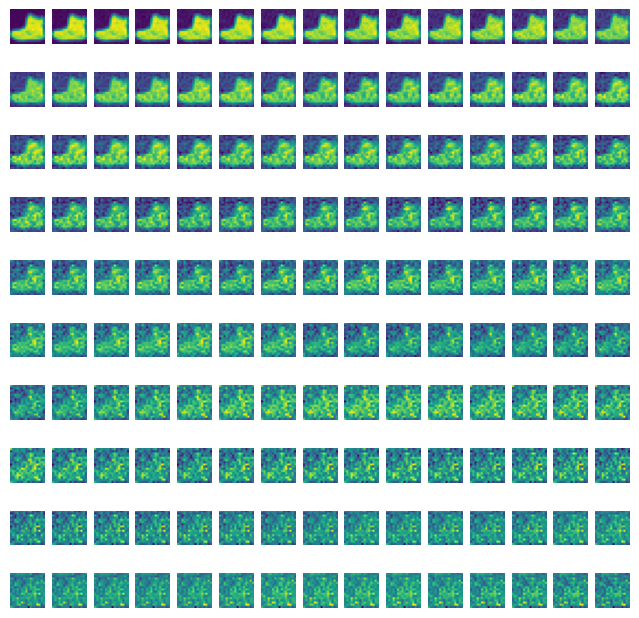

In [7]:
plt.figure(figsize=(8, 8))
x_0 = data[0][0].to(device)  # Initial image
x_t = x_0  # Set up recursion
xs = []  # Store x_t for each T to see change

for t in range(T):
    noise = torch.randn_like(x_t)
    x_t = torch.sqrt(1 - B[t]) * x_t + torch.sqrt(B[t]) * noise  # sample from q(x_t|x_t-1)
    img = torch.squeeze(x_t).cpu()
    xs.append(img)
    ax = plt.subplot(nrows, ncols, t + 1)
    ax.axis("off")
    plt.imshow(img)
plt.savefig("forward_diffusion.png", bbox_inches="tight")

Or in animated form:

MovieWriter ffmpeg unavailable; using Pillow instead.


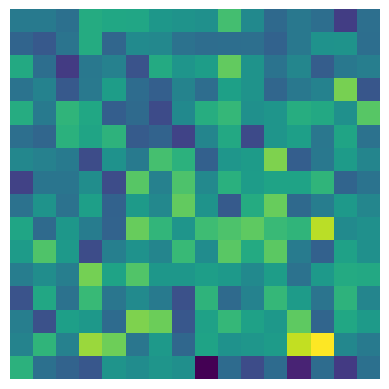

In [8]:
gif_name = "forward_diffusion.gif"
other_utils.save_animation(xs, gif_name)

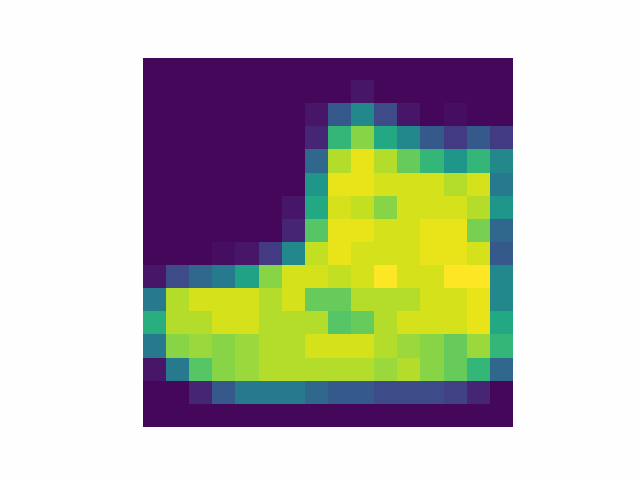

In [9]:
Image(open(gif_name,'rb').read())

## 2.2 Skipping Ahead

We could take each image of our dataset and add noise to them `T` times to create `T` more new images, but do we need to? 

Thanks to the power of recursion, we can estimate what $x_t$ would look like given our beta schedule $\beta_t$. A full breakdown of the math can be found in [Lilian Weng's Blog](https://lilianweng.github.io/posts/2021-07-11-diffusion-models/#speed-up-diffusion-model-sampling).
Let's bring back `a`lpha, which is the compliment of $\beta$. We can define $\alpha_t$ as $1 - \beta_t$, and we can define $\bar{\alpha}_t$ as the [cumulative product](https://pytorch.org/docs/stable/generated/torch.cumprod.html) of $\alpha_t$.

For example, $\bar{\alpha}_3 = \alpha_0 \cdot \alpha_1 \cdot \alpha_2 \cdot \alpha_3$

Because of the bar symbol, let's call $\bar{\alpha}_t$ `a_bar`. Our new noisy image distribution becomes:

$q(\mathbf{x}_{t}|\mathbf{x}_{0})=\mathcal{N}(\mathbf{x}_{t};\sqrt{\bar{\alpha}_{t}} \cdot x_{0},(1 - \bar{\alpha}_t) \cdot \mathbf{I})$

Which translates to code as:

`x_t = sqrt_a_bar_t * x_0 + sqrt_one_minus_a_bar_t * noise`

We are now no longer dependent on $\mathbf{x}_{t-1}$ and can estimate $\mathbf{x}_t$ from $x_0$. Let's define these variables in code:

In [10]:
a = 1. - B
a_bar = torch.cumprod(a, dim=0)
sqrt_a_bar = torch.sqrt(a_bar)  # Mean Coefficient
sqrt_one_minus_a_bar = torch.sqrt(1 - a_bar) # St. Dev. Coefficient

We have all the pieces, let's code our forward diffusion sampling function `q`:

$q(\mathbf{x}_{t}|\mathbf{x}_{0})=\mathcal{N}(\mathbf{x}_{t};\sqrt{\bar{\alpha}_{t}} \cdot \mathbf{x}_{0},(1 - \bar{\alpha}_t) \cdot \mathbf{I})$

Currently, `sqrt_a_bar` and `sqrt_one_minus_a_bar` only have one dimension, and if we index into them with `t`, they will each only have one value. If we want to multiply this value with each of the pixel values in our images, we will need to match the number of dimensions in order to [broadcast](https://numpy.org/doc/stable/user/basics.broadcasting.html).

<center><img src="images/broadcasting.png" width="60%" /></center>

We can add an extra dimension by indexing with `None`. This is a PyTorch shortcut to add an extra dimension to the resulting tensor. For reference, a batch of images has the dimensions: `batch dimension x image channels x image height x image width`.

In [11]:
def q(x_0, t):
    """
    Samples a new image from q
    Returns the noise applied to an image at timestep t
    x_0: the original image
    t: timestep
    """
    t = t.int()
    noise = torch.randn_like(x_0)
    sqrt_a_bar_t = sqrt_a_bar[t, None, None, None]
    sqrt_one_minus_a_bar_t = sqrt_one_minus_a_bar[t, None, None, None]

    x_t = sqrt_a_bar_t * x_0 + sqrt_one_minus_a_bar_t * noise
    return x_t, noise

Let's test out this new method compared to our old method of recursively generating the images.

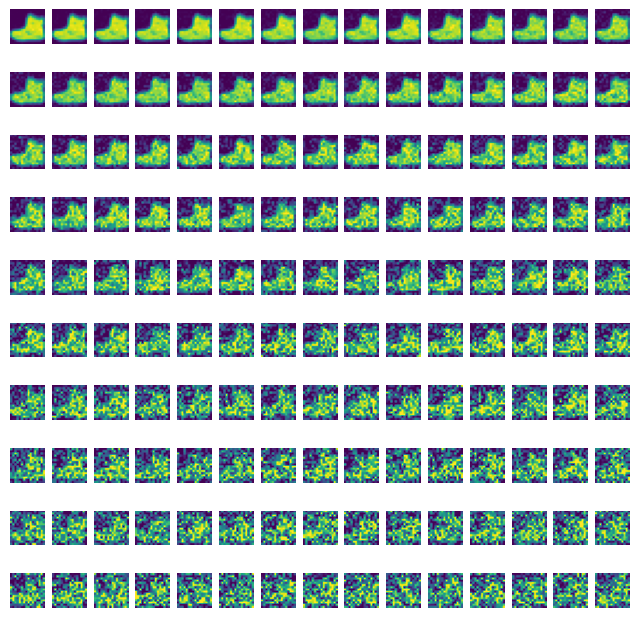

In [12]:
plt.figure(figsize=(8, 8))
xs = []

for t in range(T):
    t_tenser = torch.Tensor([t]).type(torch.int64)
    x_t, _ = q(x_0, t_tenser)
    img = torch.squeeze(x_t).cpu()
    xs.append(img)
    ax = plt.subplot(nrows, ncols, t + 1)
    ax.axis('off')
    other_utils.show_tensor_image(x_t)
plt.savefig("forward_diffusion_skip.png", bbox_inches='tight')

MovieWriter ffmpeg unavailable; using Pillow instead.


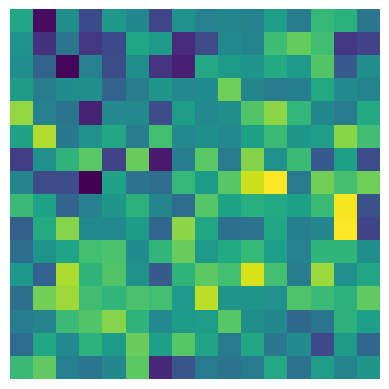

In [13]:
gif_name = "forward_diffusion_skip.gif"
other_utils.save_animation(xs, gif_name)

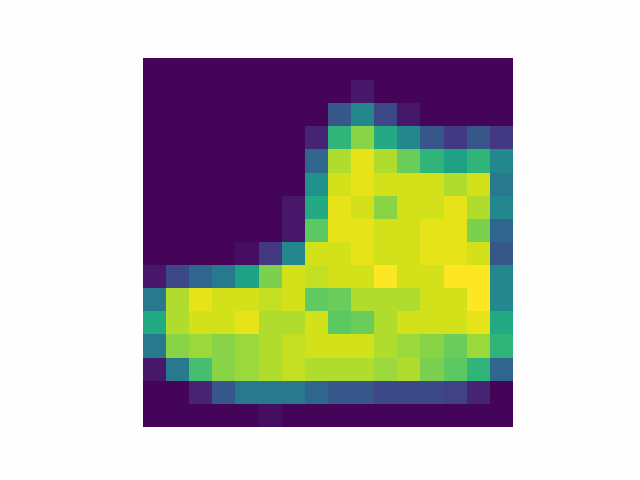

In [14]:
Image(open(gif_name,'rb').read())

Compared to the previous technique, can you see any differences? When noise is added sequentially, there is a smaller difference between the images of consecutive timesteps. Despite this, the neural network will do a good job separating the noise from the original image in the reverse diffusion process.

## 2.3 Predicting Noise

The architecture for our neural network will mostly be the same as before. However, because the amount of noise added changes with each time step, we will need a way to tell the model which time step our input image is at.

To do that, we can create an embedding block like the one below.
* `input_dim` is the number of dimensions of the value we'd like to embed. We'll be embedding `t`, which is a one-dimensional scalar.
* `emb_dim` is the number of dimensions we would like to convert our input value into by using a [Linear](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html) layer.
* [UnFlatten](https://pytorch.org/docs/stable/generated/torch.nn.Unflatten.html) is used to reshape a vector into a multidimensional space. Since we'll be adding the result of this embedding to a multidimensional feature map, we will add a few extra dimensions similar to how we expanded the dimension in the `q` function above.

In [15]:
class EmbedBlock(nn.Module):
    def __init__(self, input_dim, emb_dim):
        super().__init__()
        self.input_dim = input_dim
        layers = [
            nn.Linear(input_dim, emb_dim),
            nn.ReLU(),
            nn.Linear(emb_dim, emb_dim),
            nn.Unflatten(1, (emb_dim, 1, 1))
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, input):
        input = input.view(-1, self.input_dim)
        return self.model(input)

We will add this time embedding block to each `UpBlock` of our U-Net, resulting in the following architecture.

<center><img src="images/time_nn.png" width="80%" /></center>

In [16]:
class DownBlock(nn.Module):
    def __init__(self, in_chs, out_chs):
        kernel_size = 3
        stride = 1
        padding = 1

        super().__init__()
        layers = [
            nn.Conv2d(in_chs, out_chs, kernel_size, stride, padding),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(),
            nn.Conv2d(out_chs, out_chs, kernel_size, stride, padding),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(),
            nn.MaxPool2d(2)
        ]
        self.model = nn.Sequential(*layers)

    def forward(self, x):
        return self.model(x)

The `UpBlock` follows a similar logic, but instead uses [Transposed Convolution](https://pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html).

In [17]:
class UpBlock(nn.Module):
    def __init__(self, in_chs, out_chs):
        # Convolution variables
        kernel_size = 3
        stride = 1
        padding = 1

        # Transpose variables
        strideT = 2
        out_paddingT = 1

        super().__init__()
        # 2 * in_chs for concatenated skip connection
        layers = [
            nn.ConvTranspose2d(2 * in_chs, out_chs, kernel_size, strideT, padding, out_paddingT),
            nn.BatchNorm2d(out_chs),
            nn.ReLU(),
            nn.Conv2d(out_chs, out_chs, kernel_size, stride, padding),
            nn.BatchNorm2d(out_chs),
            nn.ReLU()
        ]
        self.model = nn.Sequential(*layers)
    
    def forward(self, x, skip):
        x = torch.cat((x, skip), 1)
        x = self.model(x)
        return x

The final U-Net is similar to what we used in the first lab. The difference is we now have a time embedding connected to our `UpBlock`s.

In [18]:
class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        img_chs = IMG_CH
        down_chs = (16, 32, 64)
        up_chs = down_chs[::-1]  # Reverse of the down channels
        latent_image_size = IMG_SIZE // 4 # 2 ** (len(down_chs) - 1)
        t_dim = 1 # New

        # Inital convolution
        self.down0 = nn.Sequential(
            nn.Conv2d(img_chs, down_chs[0], 3, padding=1),
            nn.BatchNorm2d(down_chs[0]),
            nn.ReLU()
        )

        # Downsample
        self.down1 = DownBlock(down_chs[0], down_chs[1])
        self.down2 = DownBlock(down_chs[1], down_chs[2])
        self.to_vec = nn.Sequential(nn.Flatten(), nn.ReLU())
        
        # Embeddings
        self.dense_emb = nn.Sequential(
            nn.Linear(down_chs[2]*latent_image_size**2, down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[1]),
            nn.ReLU(),
            nn.Linear(down_chs[1], down_chs[2]*latent_image_size**2),
            nn.ReLU()
        )
        self.temb_1 = EmbedBlock(t_dim, up_chs[0])  # New
        self.temb_2 = EmbedBlock(t_dim, up_chs[1])  # New
        
        # Upsample
        self.up0 = nn.Sequential(
            nn.Unflatten(1, (up_chs[0], latent_image_size, latent_image_size)),
            nn.Conv2d(up_chs[0], up_chs[0], 3, padding=1),
            nn.BatchNorm2d(up_chs[0]),
            nn.ReLU(),
        )
        self.up1 = UpBlock(up_chs[0], up_chs[1])
        self.up2 = UpBlock(up_chs[1], up_chs[2])

        # Match output channels
        self.out = nn.Sequential(
            nn.Conv2d(up_chs[-1], up_chs[-1], 3, 1, 1),
            nn.BatchNorm2d(up_chs[-1]),
            nn.ReLU(),
            nn.Conv2d(up_chs[-1], img_chs, 3, 1, 1)
        )

    def forward(self, x, t):
        down0 = self.down0(x)
        down1 = self.down1(down0)
        down2 = self.down2(down1)
        latent_vec = self.to_vec(down2)
        
        # New
        t = t.float() / T  # Convert from [0, T] to [0, 1]
        latent_vec = self.dense_emb(latent_vec)
        temb_1 = self.temb_1(t)
        temb_2 = self.temb_2(t)

        up0 = self.up0(latent_vec)
        up1 = self.up1(up0+temb_1, down2)
        up2 = self.up2(up1+temb_2, down1)
        return self.out(up2)

In [19]:
model = UNet()
print("Num params: ", sum(p.numel() for p in model.parameters()))
model = torch.compile(UNet().to(device))

Num params:  240385


### 2.3.1 The Loss Function

In the first notebook, we used a [Mean Squared Error](https://developers.google.com/machine-learning/glossary#mean-squared-error-mse) loss function comparing the original image and the predicted original image based on noise.

This time, we'll compare the real noise that was added to the image and the predicted noise. Lilian Weng goes into the math in this [blog post](https://lilianweng.github.io/posts/2021-07-11-diffusion-models/#parameterization-of-l_t-for-training-loss). Originally, the loss function was based on the [Evidence Lower Bound (ELBO)](https://en.wikipedia.org/wiki/Evidence_lower_bound) [Log-Likelihood](https://mathworld.wolfram.com/Log-LikelihoodFunction.html), but it was found in the [Denoising Diffusion Probabilistic Models Paper](https://arxiv.org/abs/2006.11239) that the Mean Squared Error between the predicted noise and true noise was better in practice. If curious, Lilian Weng walks through the derivation [here](https://lilianweng.github.io/posts/2021-07-11-diffusion-models/#reverse-diffusion-process).

In [20]:
def get_loss(model, x_0, t):
    x_noisy, noise = q(x_0, t)
    noise_pred = model(x_noisy, t)
    return F.mse_loss(noise, noise_pred)

## 2.4 Reverse Diffusion

We now have a model that predicts the noise added to an image at timestep `t`, but generating images is not as easy as repeatedly subtracting and adding noise. The `q` function can be reversed such that we generate $\mathbf{x}_(t-1)$ from $\mathbf{x}_t$.

$q(\mathbf{x}_{t}|\mathbf{x}_{t-1}) = \mathcal{N}(\mathbf{x}_{t-1};{\mathbf{\tilde{\mu}}}(\mathbf{x_t},\mathbf{x_0}), \tilde{\beta}_t \cdot \mathbf{I})$

**Note**: $\tilde{\beta}_t$ was originally calculated to be $\frac{1-\overline{a}_{t-1}}{1-\overline{a}_{t}}\beta_t$, but in practice, using only $\beta_t$ is more effective.

Using [Bayes' Theorem](https://en.wikipedia.org/wiki/Bayes%27_theorem), we can derive an equation for the model_mean `u_t` at timestep `t`.

${\mathbf{\tilde{\mu}}}_t = \frac{1}{\sqrt{\alpha_t}}(\mathbf{x_t}-\frac{1-\alpha_t}{\sqrt{1-\overline{\alpha_t}}}\mathbf{\epsilon}_t)$

The image $\mathbf{x}_{t-1}$ can be estimated by ${\mathbf{\tilde{\mu}}}_t + \tilde{\beta}_t \cdot \mathbf{I}$, so we'll use this equation to generate sample images recursively until we reach `t == 0`. Let's see what this means in code. First, we will precompute the values needed to calculate `u_t`.

In [26]:
sqrt_a_inv = torch.sqrt(1 / a)
pred_noise_coeff = (1 - a) / torch.sqrt(1 - a_bar)

Next, we will create the reverse diffusion function, `reverse_q`.

In [23]:
@torch.no_grad()
def reverse_q(x_t, t, e_t):
    t = torch.squeeze(t[0].int())  # All t values should be the same
    pred_noise_coeff_t = pred_noise_coeff[t]
    sqrt_a_inv_t = sqrt_a_inv[t]
    u_t = sqrt_a_inv_t * (x_t - pred_noise_coeff_t * e_t)
    if t == 0:
        return u_t  # Reverse diffusion complete!
    else:
        B_t = B[t-1]
        new_noise = torch.randn_like(x_t)
        return u_t + torch.sqrt(B_t) * new_noise

Let's create a function to iteratively remove noise from an image until it is noise free. Let's also display these images so we can see how the model is improving.

In [24]:
@torch.no_grad()
def sample_images(ncols, figsize=(8,8)):
    plt.figure(figsize=figsize)
    plt.axis("off")
    hidden_rows = T / ncols

    # Noise to generate images from
    x_t = torch.randn((1, IMG_CH, IMG_SIZE, IMG_SIZE), device=device)

    # Go from T to 0 removing and adding noise until t = 0
    plot_number = 1
    for i in range(0, T)[::-1]:
        t = torch.full((1,), i, device=device)
        e_t = model(x_t, t)  # Predicted noise
        x_t = reverse_q(x_t, t, e_t)
        if i % hidden_rows == 0:
            ax = plt.subplot(1, ncols+1, plot_number)
            ax.axis('off')
            other_utils.show_tensor_image(x_t.detach().cpu())
            plot_number += 1
    plt.show()

Time to train the model! How about it? Does it look like the model is learning?

Epoch 0 | Step 000 | Loss: 1.1899447441101074 


/tmp/ipykernel_40/3817596156.py:17: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  ax = plt.subplot(1, ncols+1, plot_number)


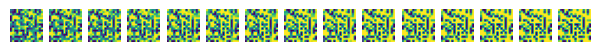

Epoch 0 | Step 100 | Loss: 0.4245002269744873 


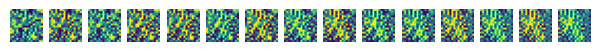

Epoch 0 | Step 200 | Loss: 0.27957940101623535 


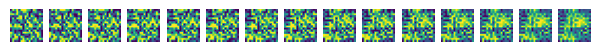

Epoch 0 | Step 300 | Loss: 0.2579854726791382 


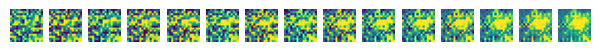

Epoch 0 | Step 400 | Loss: 0.23212598264217377 


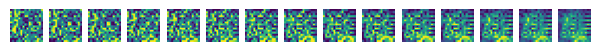

Epoch 0 | Step 500 | Loss: 0.21233579516410828 


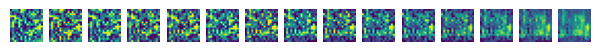

Epoch 1 | Step 000 | Loss: 0.19538970291614532 


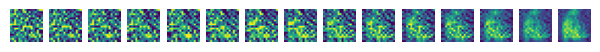

Epoch 1 | Step 100 | Loss: 0.21276450157165527 


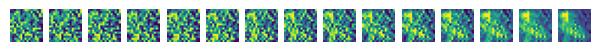

Epoch 1 | Step 200 | Loss: 0.1669658124446869 


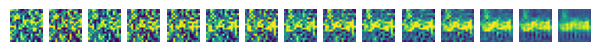

Epoch 1 | Step 300 | Loss: 0.1890161782503128 


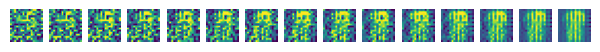

Epoch 1 | Step 400 | Loss: 0.18946869671344757 


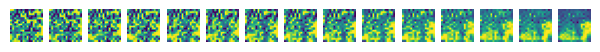

Epoch 1 | Step 500 | Loss: 0.1987648904323578 


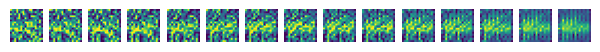

Epoch 2 | Step 000 | Loss: 0.16789314150810242 


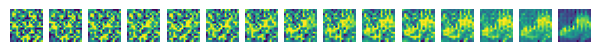

Epoch 2 | Step 100 | Loss: 0.1783234030008316 


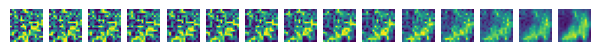

Epoch 2 | Step 200 | Loss: 0.17445459961891174 


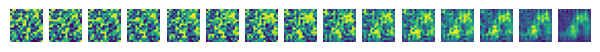

Epoch 2 | Step 300 | Loss: 0.1656389832496643 


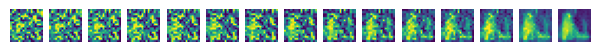

Epoch 2 | Step 400 | Loss: 0.16008707880973816 


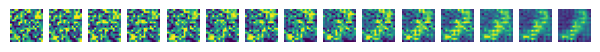

Epoch 2 | Step 500 | Loss: 0.160152867436409 


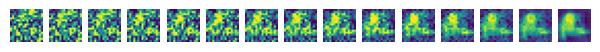

Final sample:


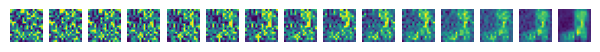

In [27]:
optimizer = Adam(model.parameters(), lr=0.001)
epochs = 3
ncols = 15  # Should evenly divide T

model.train()
for epoch in range(epochs):
    for step, batch in enumerate(dataloader):
        optimizer.zero_grad()

        t = torch.randint(0, T, (BATCH_SIZE,), device=device)
        x = batch[0].to(device)
        loss = get_loss(model, x, t)
        loss.backward()
        optimizer.step()

        if epoch % 1 == 0 and step % 100 == 0:
            print(f"Epoch {epoch} | Step {step:03d} | Loss: {loss.item()} ")
            sample_images(ncols)
print("Final sample:")
sample_images(ncols)

If you squint your eyes, can you make out what the model is generating?

/tmp/ipykernel_40/3817596156.py:17: MatplotlibDeprecationWarning: Auto-removal of overlapping axes is deprecated since 3.6 and will be removed two minor releases later; explicitly call ax.remove() as needed.
  ax = plt.subplot(1, ncols+1, plot_number)


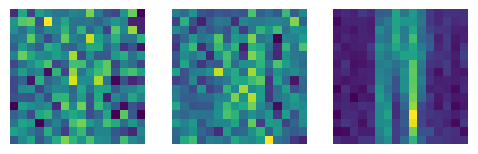

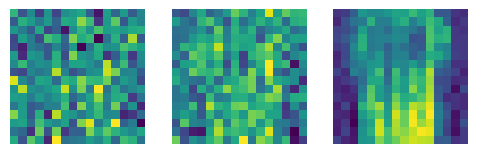

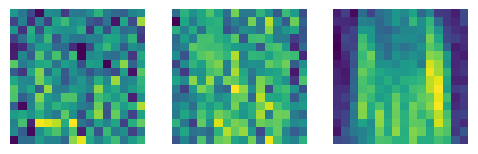

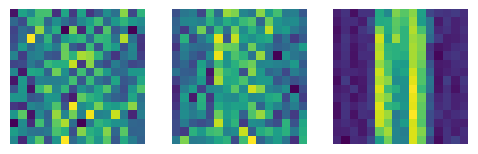

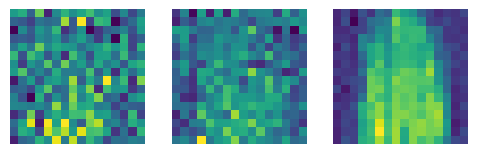

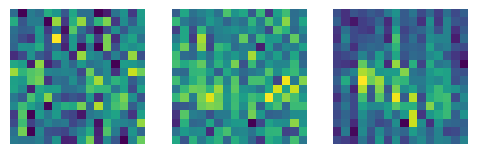

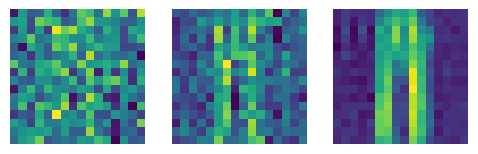

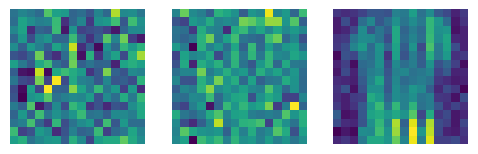

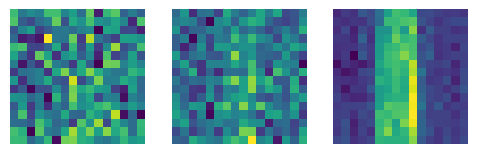

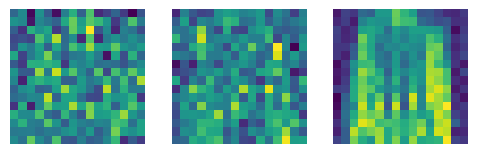

In [28]:
model.eval()
figsize=(8,8) # Change me
ncols = 3 # Should evenly divide T
for _ in range(10):
    sample_images(ncols, figsize=figsize)

## 2.5 Next

The model is learning ... something. It looks a little pixelated. Why would that be? Continue to the next notebook to find out more!

In [ ]:
import IPython
app = IPython.Application.instance()
app.kernel.do_shutdown(True)

<center><a href="https://www.nvidia.com/en-us/training/"><img src="https://dli-lms.s3.amazonaws.com/assets/general/DLI_Header_White.png" width="400" height="186" /></a></center>